<a href="https://colab.research.google.com/github/oviyas2025cse-rec/AFIS/blob/main/VoltRelay_Final_Complete_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VoltRelay Energy | Data Analytics Hackathon

## What is happening across the battery-swap network?

**Analysis notebook · Student analyst submission**  
**Dataset used:** `datahackthon.zip` supplied for the challenge  
**Records analysed:** 1,048,575 swap attempts  
**Observed period:** 1 January – 22 August 2024

### My objective

I approached this as an operations analysis: first establish how the network is performing, then look for where service problems are concentrated, and finally check whether battery, pricing, partner and early rider-experience patterns help explain the business picture.

I have kept the analysis tied to the columns available in the supplied files. Where a comparison is only an association, I describe it that way rather than presenting it as proof of cause.

### Dataset coverage matters

The challenge brief describes 3,877,013 swap events through 30 June 2025. The ZIP available to me contains 1,048,575 events through 22 August 2024. I have analysed the supplied records as they are and have not created or estimated missing rows. This means I cannot verify the later 2025 trends or the full 18-month business story from this extract.

One more definition is important: the contribution estimate in this notebook subtracts estimated recharge-energy cost from revenue. It does **not** include rent, maintenance, labour, battery depreciation, payment fees or overhead, so it must not be read as net profit or full contribution margin.


## How I have organised the investigation

| Business question | What I measured | How to read the result |
|---|---|---|
| 1. Network performance | Attempts, completed swaps, revenue, failure rate and energy-only contribution per completed swap | The available period is shorter than the period in the brief; the contribution figure is not full profit |
| 2. Service experience | Event outcomes, queue wait, hour, city, vehicle class and station characteristics | Segment differences show where to investigate; they do not establish cause |
| 3. Station and geography | Station-level failure and wait rates, expansion groups, telemetry and station-linked tickets | I check activity volume before ranking stations so small samples do not dominate |
| 4. Battery and equipment | Supplier, manufacturing lot, state of health, recorded range and retirement information | The battery register is a snapshot, not a complete event-by-event battery history |
| 5. Pricing and partners | Tariff mix, realised prices and partner-level energy-only contribution | The 2025 pricing pilot and full partner profitability cannot be tested from this event extract |
| 6. New-rider retention | 30-day repeat use after first successful swap and experience before that first success | This is a defined cohort measure, not a direct estimate of the company-wide churn trend |

I have also included the optional budget, expansion, partner-value, ticket-text and anomaly checks where the available fields support them.


## 1. Load the dataset

I start with the ZIP supplied for the hackathon. In Google Colab, the next cell asks me to upload that ZIP and extracts it into a working folder. The same notebook also supports the local verification copy used to test the analysis.


In [1]:
import zipfile, os, glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Detect whether this notebook is running in Google Colab.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Upload the datahackthon.zip file supplied for the hackathon.")
    uploaded = files.upload()
    zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
    if not zip_files:
        raise FileNotFoundError("Please upload the supplied ZIP file.")
    extract_dir = "/content/volt_relay_data"
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_files[0], "r") as archive:
        archive.extractall(extract_dir)
else:
    # Local path used only to verify the notebook outside Colab.
    extract_dir = "/mnt/data/volt_relay_execution_check"
    if not os.path.isdir(extract_dir):
        raise FileNotFoundError("Dataset folder not found. Run this notebook in Colab and upload datahackthon.zip.")

print("Dataset files found:")
for file_path in glob.glob(extract_dir + "/**/*", recursive=True):
    if os.path.isfile(file_path):
        print("-", os.path.basename(file_path))

# Consistent chart settings make comparisons easier to read.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25
})
pd.set_option("display.max_columns", 30)


Upload the datahackthon.zip file supplied for the hackathon.


Saving datahackthon.zip to datahackthon.zip
Dataset files found:
- fleet_partners.csv
- stations.csv
- riders.csv
- station_hourly_status.csv
- compressed_data.csv.gz
- city_daily_context.csv
- batteries.csv
- support_tickets.csv


## 2. Read the eight datasets

The swap-events table is the main fact table: one row represents one attempt, whether it succeeded or not. The remaining tables add context about riders, stations, batteries, support, operating conditions and fleet partners.

Before joining anything, I check the row and column counts. This helps me understand the size and level of detail of each table, and reduces the risk of accidentally multiplying swap records during a join.


In [2]:
def locate_file(file_name):
    matches = glob.glob(extract_dir + "/**/" + file_name, recursive=True)
    if not matches:
        raise FileNotFoundError(f"{file_name} was not found in the uploaded ZIP.")
    return matches[0]

sw = pd.read_csv(locate_file("compressed_data.csv.gz"), compression="gzip", low_memory=False)
riders = pd.read_csv(locate_file("riders.csv"))
stations = pd.read_csv(locate_file("stations.csv"))
batteries = pd.read_csv(locate_file("batteries.csv"))
tickets = pd.read_csv(locate_file("support_tickets.csv"))
telemetry = pd.read_csv(locate_file("station_hourly_status.csv"))
city_context = pd.read_csv(locate_file("city_daily_context.csv"))
partners = pd.read_csv(locate_file("fleet_partners.csv"))

# Categories reduce memory use for repeated labels in the large event table.
for col in ["event_type", "tariff_code", "payment_mode", "station_firmware", "sync_mode"]:
    sw[col] = sw[col].astype("category")
for frame, cols in [(stations, ["city", "zone", "location_type", "host_type", "expansion_wave", "charger_generation", "connectivity_tier"]),
                    (riders, ["vehicle_class", "signup_channel", "plan_type", "declared_shift", "age_band"])]:
    for col in cols:
        frame[col] = frame[col].astype("category")

for name, frame in {"swap events":sw,"riders":riders,"stations":stations,"batteries":batteries,
                    "support tickets":tickets,"station telemetry":telemetry,"city context":city_context,
                    "fleet partners":partners}.items():
    print(f"{name:20s} {frame.shape[0]:>10,} rows | {frame.shape[1]:>2} columns")

swap events           1,048,575 rows | 22 columns
riders                   20,000 rows | 12 columns
stations                    152 rows | 22 columns
batteries                 6,500 rows | 13 columns
support tickets          44,000 rows | 12 columns
station telemetry     1,487,712 rows | 14 columns
city context              3,282 rows | 12 columns
fleet partners               12 rows | 12 columns


## 3. Understand the data before calculating KPIs

A **row's grain** is what one row represents. Here, one swap-event row is one attempt; one telemetry row is one station-hour; and one ticket row is one support case. These are not interchangeable levels of detail.

I parse the event timestamp and create month, hour, date and weekday fields for time-based comparisons. When I later use telemetry or tickets with event data, I aggregate them to a compatible level first rather than joining raw one-to-many tables directly to every swap.


In [3]:
sw["event_ts"] = pd.to_datetime(sw["event_ts"], format="%d-%m-%Y %H:%M", errors="coerce")
sw["month"] = sw["event_ts"].dt.to_period("M").astype(str)
sw["hour"] = sw["event_ts"].dt.hour
sw["date"] = sw["event_ts"].dt.date
sw["weekday"] = sw["event_ts"].dt.day_name()
print("Event rows:", f"{len(sw):,}")
print("Observed period:", sw["event_ts"].min(), "to", sw["event_ts"].max())
display(sw["event_type"].value_counts(dropna=False).to_frame("attempts"))

Event rows: 1,048,575
Observed period: 2024-01-01 00:00:00 to 2024-08-22 23:55:00


,attempts
event_type,
swap_completed,979362
failed_no_charged_battery,40902
abandoned_queue,20736
cancelled_by_rider,4457
failed_system_error,3118


## 4. Data quality checks

I check missing values, duplicate identifiers, unusual state-of-charge readings, distance outliers and the values in `attempt_seq` and `sync_mode`.

A missing value is not automatically an error. For example, a failed attempt may not have an issued battery or recharge-energy value. Likewise, a missing telemetry reading is not the same as zero stock or zero outage. I keep the original records and create flags for suspicious values so the issue remains visible during interpretation.


In [4]:
quality = pd.DataFrame({
    'missing_pct': sw.isna().mean().mul(100),
    'dtype': sw.dtypes.astype(str)
}).sort_values('missing_pct', ascending=False)
print(quality.head(15))
print('Duplicate event IDs:', sw['event_id'].duplicated().sum())
print('Duplicate full rows:', sw.duplicated().sum())
print('SOC above 100:', ((sw['soc_in_pct'] > 100) | (sw['soc_out_pct'] > 100)).sum())
print('Negative / extreme odometer values:', ((sw['km_since_last_swap'] < 0) | (sw['km_since_last_swap'] > 500)).sum())
print('Attempt sequence values:', sw['attempt_seq'].value_counts(dropna=False).to_dict())
print('Sync mode:', sw['sync_mode'].value_counts(dropna=False).to_dict())
# Keep raw values; create flags instead of silently deleting records
sw['soc_out_of_range_flag'] = (sw['soc_in_pct'] > 100) | (sw['soc_out_pct'] > 100) | (sw['soc_in_pct'] < 0) | (sw['soc_out_pct'] < 0)
sw['odometer_outlier_flag'] = (sw['km_since_last_swap'] < 0) | (sw['km_since_last_swap'] > 500)
sw['duplicate_event_flag'] = sw['event_id'].duplicated(keep=False)


                        missing_pct           dtype
battery_out_id             6.600672          object
soc_out_pct                6.600672         float64
soh_out_pct                6.600672         float64
energy_to_recharge_kwh     6.600672         float64
soc_in_pct                 0.722409         float64
km_since_last_swap         0.722409         float64
soh_in_pct                 0.722409         float64
battery_in_id              0.722409          object
rider_id                   0.000000          object
event_id                   0.000000          object
queue_wait_sec             0.000000           int64
event_ts                   0.000000  datetime64[ns]
event_type                 0.000000        category
attempt_seq                0.000000           int64
station_id                 0.000000          object
Duplicate event IDs: 0
Duplicate full rows: 0
SOC above 100: 975
Negative / extreme odometer values: 2082
Attempt sequence values: {1: 1048575}
Sync mode: {'realtime': 

## 5. Join the supporting tables and define the measures

I join station and rider attributes to the swap table using their IDs. I use many-to-one validation because each event should match one station and one rider; the printed unmatched counts are a quick check that the joins behaved as expected.

For completed swaps, I estimate recharge-energy cost as:

\[	ext{Estimated energy cost} = 	ext{energy to recharge (kWh)} 	imes 	ext{station grid tariff}\]

Then:

\[	ext{Energy-only contribution} = 	ext{amount charged} - 	ext{estimated energy cost}\]

This is a deliberately narrow cost measure. It is useful for comparing the energy component, but it is not the full cost of operating a station or serving a rider.


In [5]:
station_cols = ["station_id","city","zone","location_type","host_type","expansion_wave","charger_generation","connectivity_tier","grid_tariff_inr_kwh","monthly_rent_inr","monthly_maintenance_inr"]
rider_cols = ["rider_id","partner_id","vehicle_class","vehicle_model","home_zone","signup_date","signup_channel","plan_type","declared_shift","age_band","kyc_verified","home_city"]
analysis = sw.merge(stations[station_cols], on="station_id", how="left", validate="many_to_one")
analysis = analysis.merge(riders[rider_cols], on="rider_id", how="left", validate="many_to_one")
analysis["completed"] = analysis["event_type"].eq("swap_completed")
analysis["failed"] = ~analysis["completed"]
analysis["energy_cost_inr"] = analysis["energy_to_recharge_kwh"] * analysis["grid_tariff_inr_kwh"]
month_num = analysis["event_ts"].dt.month
analysis["season"] = np.select([month_num.isin([12,1,2]),month_num.isin([3,4,5]),month_num.isin([6,7,8,9]),month_num.isin([10,11])], ["Winter","Summer","Monsoon","Post-monsoon"], default="Unknown")
completed = analysis[analysis["completed"]].copy()
print("Unmatched station rows:", f"{analysis['city'].isna().sum():,}")
print("Unmatched rider rows:", f"{analysis['vehicle_class'].isna().sum():,}")
print("Completed swaps:", f"{len(completed):,}")

Unmatched station rows: 0
Unmatched rider rows: 0
Completed swaps: 979,362


## 6. Core question 1 — How has the network performed?

I compare monthly attempts and completed swaps with revenue, failure rate and the energy-only contribution estimate. I keep the number of completed swaps beside the money measures because a revenue increase can simply reflect higher volume.

The charts are intended to show whether volume, service reliability and the per-swap estimate move together or tell different stories. I would not describe the last metric as profit because several important operating costs are not available in the calculation.


,attempts,completed,failure_rate,revenue_inr,energy_cost_inr,completed_swaps,contribution_before_fixed_per_swap
month,,,,,,,
2024-01,110348,105490,0.044,6318995.2,2320971.243,105490,37.900
2024-02,111531,106582,0.044,6387614.8,2334290.439,106582,38.030
2024-03,123900,118444,0.044,7093617.0,2572346.557,118444,38.172
2024-04,131818,122836,0.068,7370255.8,2652598.932,122836,38.406
2024-05,146278,128328,0.123,7689594.0,2738029.260,128328,38.585
2024-06,148888,133743,0.102,8003275.6,2813405.938,133743,38.805
2024-07,158688,151824,0.043,9879524.6,3166309.814,151824,44.217
2024-08,117124,112115,0.043,7289408.9,2317620.343,112115,44.345


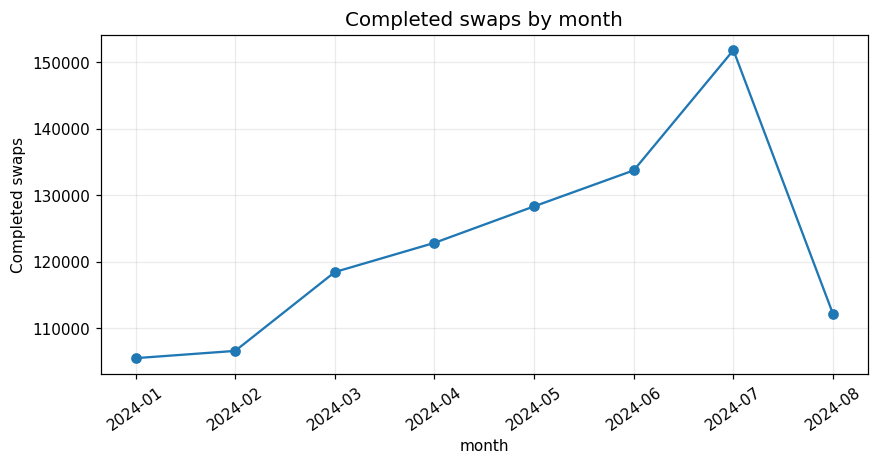

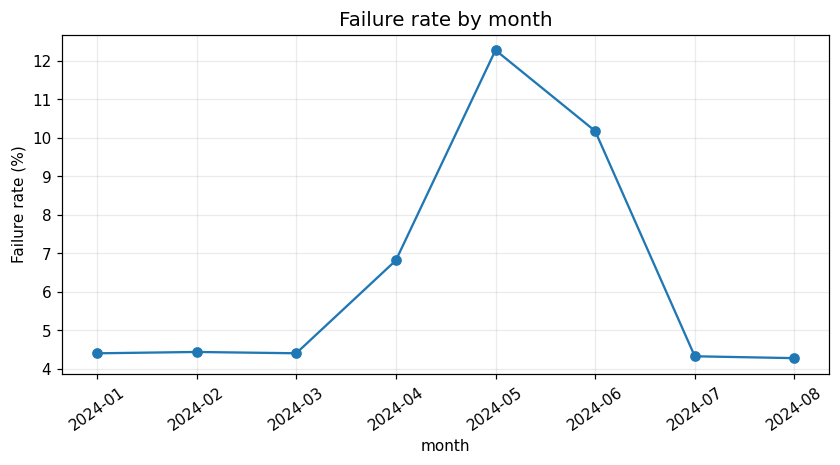

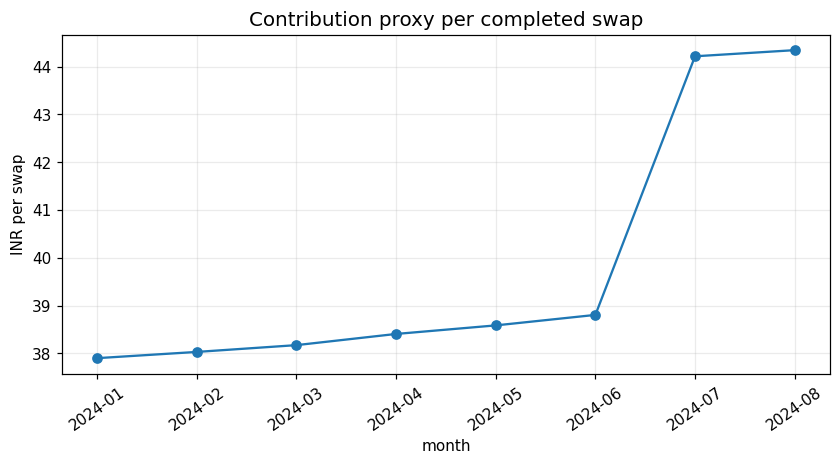

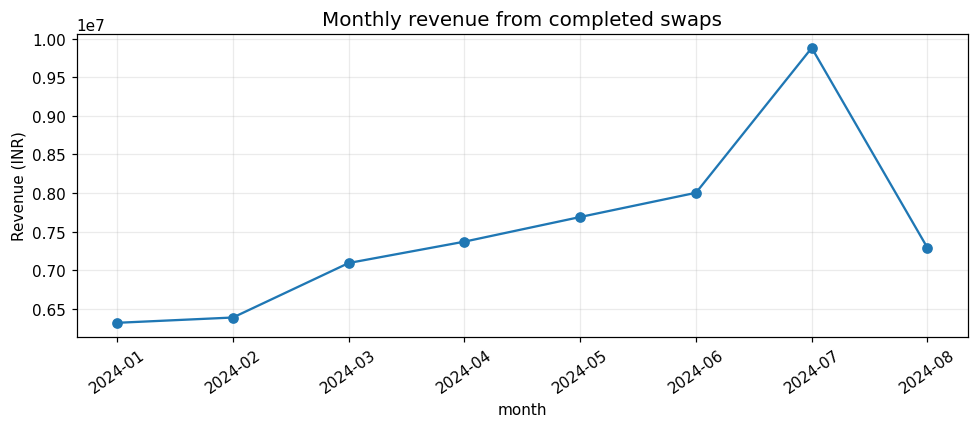

In [6]:
monthly_attempts = analysis.groupby('month').agg(attempts=('event_id','size'), completed=('completed','sum'), failure_rate=('failed','mean'))
monthly_money = completed.groupby('month').agg(revenue_inr=('amount_charged_inr','sum'), energy_cost_inr=('energy_cost_inr','sum'), completed_swaps=('event_id','size'))
monthly = monthly_attempts.join(monthly_money)
monthly['contribution_before_fixed_per_swap'] = (monthly['revenue_inr'] - monthly['energy_cost_inr']) / monthly['completed_swaps']
display(monthly.round(3))
monthly['completed'].plot(marker='o', title='Completed swaps by month', figsize=(9,4)); plt.ylabel('Completed swaps'); plt.xticks(rotation=35); plt.show()
(monthly['failure_rate']*100).plot(marker='o', title='Failure rate by month', figsize=(9,4)); plt.ylabel('Failure rate (%)'); plt.xticks(rotation=35); plt.show()
monthly['contribution_before_fixed_per_swap'].plot(marker='o', title='Contribution proxy per completed swap', figsize=(9,4)); plt.ylabel('INR per swap'); plt.xticks(rotation=35); plt.show()

monthly["revenue_inr"].plot(marker="o", title="Monthly revenue from completed swaps", figsize=(9,4))
plt.ylabel("Revenue (INR)"); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

## 7. Core question 2 — Where do service problems appear?

I begin with the mix of recorded outcomes, then compare failure rates and average queue waits across city, vehicle class, location type, charger generation, connectivity, hour and season.

Averages can hide important differences, so I look at the segment's attempt count as well as its rate. I also separate queue abandonment from other non-completed outcomes: abandonment is especially relevant to the rider's waiting experience, while system errors and lack of charged stock may need different operational responses.


,attempts,share_pct
event_type,,
swap_completed,979362,93.40
failed_no_charged_battery,40902,3.90
abandoned_queue,20736,1.98
cancelled_by_rider,4457,0.43
failed_system_error,3118,0.30



Performance by city


,attempts,avg_queue_wait_sec,failure_rate_pct
city,,,
Jaipur,129406,243.16,9.77
Delhi NCR,195292,242.87,8.46
Hyderabad,187212,242.57,7.71
Pune,158349,242.83,5.23
Bengaluru,232468,242.89,4.65
Mumbai,145848,242.83,4.46



Performance by vehicle_class


,attempts,avg_queue_wait_sec,failure_rate_pct
vehicle_class,,,
3W,121665,242.57,10.82
2W,926910,242.88,6.05



Performance by location_type


... (5 outputs left out)


Performance by hour


,attempts,avg_queue_wait_sec,failure_rate_pct
hour,,,
21,100169,242.62,7.55
20,126149,242.47,7.47
19,125964,243.20,7.38
22,50591,241.51,7.37
15,27464,241.34,6.69
11,27649,243.18,6.59
16,28177,241.59,6.49
17,33134,244.09,6.38
3,5905,242.45,6.32



Performance by season


,attempts,avg_queue_wait_sec,failure_rate_pct
season,,,
Summer,401996,242.77,8.06
Monsoon,424700,242.90,6.36
Winter,221879,242.88,4.42


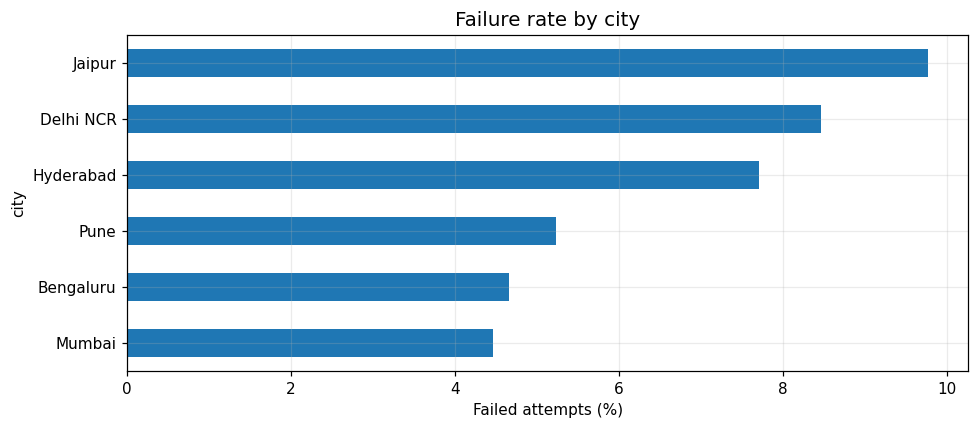

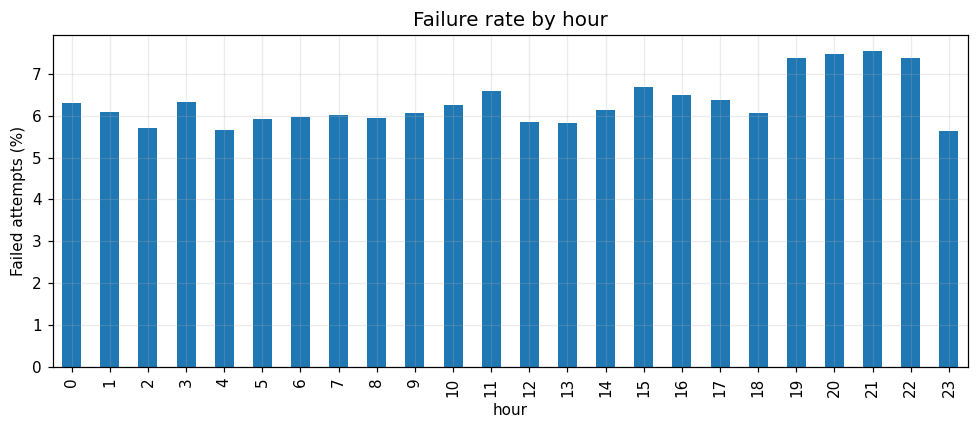

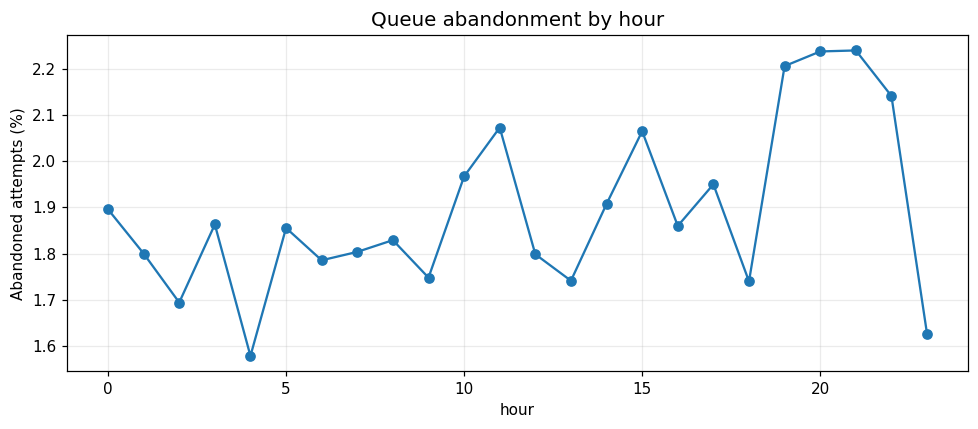

In [7]:
outcome_mix = analysis["event_type"].value_counts(dropna=False).to_frame("attempts")
outcome_mix["share_pct"] = outcome_mix["attempts"] / len(analysis) * 100
display(outcome_mix.round(2))

for segment in ["city","vehicle_class","location_type","charger_generation","connectivity_tier","hour","season"]:
    result = analysis.groupby(segment, dropna=False, observed=True).agg(
        attempts=("event_id","size"), failure_rate=("failed","mean"),
        avg_queue_wait_sec=("queue_wait_sec","mean")).sort_values("failure_rate",ascending=False)
    result["failure_rate_pct"] = result["failure_rate"] * 100
    print("\nPerformance by", segment)
    display(result.drop(columns="failure_rate").round(2))

city_rates = analysis.groupby("city", observed=True)["failed"].mean().mul(100).sort_values()
city_rates.plot(kind="barh", title="Failure rate by city", figsize=(9,4)); plt.xlabel("Failed attempts (%)"); plt.tight_layout(); plt.show()
hour_rates = analysis.groupby("hour")["failed"].mean().mul(100)
hour_rates.plot(kind="bar", title="Failure rate by hour", figsize=(9,4)); plt.ylabel("Failed attempts (%)"); plt.tight_layout(); plt.show()
abandon = analysis.assign(abandoned=analysis["event_type"].eq("abandoned_queue")).groupby("hour")["abandoned"].mean().mul(100)
abandon.plot(marker="o", title="Queue abandonment by hour", figsize=(9,4)); plt.ylabel("Abandoned attempts (%)"); plt.tight_layout(); plt.show()

## 8. Core question 3 — Which stations and areas need attention?

I calculate station-level attempts, failure rate and average wait. For the ranked list, I keep stations with at least 1,000 attempts so that a station with only a handful of events is not automatically treated as the worst performer.

I then compare expansion groups and summarise hourly telemetry at station level before linking it to station attributes. Finally, I compare station-linked tickets per 1,000 attempts. These measures help shortlist locations for investigation; they do not by themselves tell us whether stock, chargers, power or connectivity caused the problem.


In [8]:
station_kpis = analysis.groupby(["station_id","city","location_type","expansion_wave","charger_generation"], observed=True).agg(
    attempts=("event_id","size"), failure_rate=("failed","mean"), avg_wait_sec=("queue_wait_sec","mean")).reset_index()
station_kpis = station_kpis[station_kpis["attempts"] >= 1000].sort_values("failure_rate",ascending=False)
print("Highest failure-rate stations (minimum 1,000 attempts):"); display(station_kpis.head(20).round(3))
print("Expansion-wave comparison:"); display(analysis.groupby("expansion_wave",observed=True).agg(attempts=("event_id","size"),completed=("completed","sum"),failure_rate=("failed","mean")).round(4))

telemetry_station = telemetry.groupby("station_id").agg(mean_outage_minutes=("outage_minutes","mean"),mean_quarantined=("packs_quarantined","mean"),mean_chargers_online=("chargers_online","mean"),mean_charge_minutes=("avg_charge_minutes","mean")).reset_index()
station_telemetry = stations[station_cols].merge(telemetry_station,on="station_id",how="left",validate="one_to_one")
display(station_telemetry.groupby("city",observed=True).agg(mean_outage=("mean_outage_minutes","mean"),mean_quarantined=("mean_quarantined","mean"),mean_charge_minutes=("mean_charge_minutes","mean")).round(2))

station_ticket_counts = tickets.dropna(subset=["station_id"]).groupby("station_id").size().rename("tickets")
station_complaints = station_kpis.merge(station_ticket_counts,on="station_id",how="left")
station_complaints["tickets"] = station_complaints["tickets"].fillna(0)
station_complaints["tickets_per_1000_attempts"] = station_complaints["tickets"] / station_complaints["attempts"] * 1000
print("Station-linked tickets per 1,000 attempts:"); display(station_complaints.sort_values("tickets_per_1000_attempts",ascending=False).head(15).round(2))

# Join city context at city-day grain, not at the 1-million-row event grain.
daily_city = analysis.groupby(["city","date"],observed=True).agg(attempts=("event_id","size"),failed_attempts=("failed","sum")).reset_index()
daily_city["failure_rate"] = daily_city["failed_attempts"] / daily_city["attempts"]
city_context["date"] = pd.to_datetime(city_context["date"],errors="coerce").dt.date
daily_context = daily_city.merge(city_context,on=["city","date"],how="left",validate="many_to_one")
display(daily_context.groupby(["heat_alert","flood_disruption"],dropna=False).agg(city_days=("date","size"),attempts=("attempts","sum"),mean_daily_failure_rate=("failure_rate","mean")).round(3))

Highest failure-rate stations (minimum 1,000 attempts):


,station_id,city,location_type,expansion_wave,charger_generation,attempts,failure_rate,avg_wait_sec
61,STN-JAI-138,Jaipur,market,Launch,Gen1,15509,0.104,243.754
24,STN-DEL-037,Delhi NCR,commercial_hub,Launch,Gen1,9681,0.101,239.721
60,STN-JAI-137,Jaipur,commercial_hub,Launch,Gen1,14112,0.099,242.938
62,STN-JAI-139,Jaipur,commercial_hub,Launch,Gen1,11775,0.099,244.722
57,STN-JAI-134,Jaipur,commercial_hub,Launch,Gen1,14042,0.098,241.916
65,STN-JAI-142,Jaipur,commercial_hub,Launch,Gen1,11708,0.097,244.197
56,STN-JAI-133,Jaipur,market,Launch,Gen1,10491,0.097,244.017
63,STN-JAI-140,Jaipur,commercial_hub,Launch,Gen1,14653,0.096,242.364
32,STN-DEL-045,Delhi NCR,commercial_hub,Launch,Gen1,8944,0.096,243.426
59,STN-JAI-136,Jaipur,transit_hub,Launch,Gen1,10611,0.095,241.287


Expansion-wave comparison:


,attempts,completed,failure_rate
expansion_wave,,,
Launch,1046993,977844,0.0660
Wave1_2024H2,1582,1518,0.0405


,mean_outage,mean_quarantined,mean_charge_minutes
city,,,
Bengaluru,0.01,0.0,65.96
Delhi NCR,0.01,0.0,72.18
Hyderabad,0.01,0.0,71.83
Jaipur,0.01,0.0,75.20
Mumbai,0.04,0.0,61.21
Pune,0.01,0.0,62.64


Station-linked tickets per 1,000 attempts:


,station_id,city,location_type,expansion_wave,charger_generation,attempts,failure_rate,avg_wait_sec,tickets,tickets_per_1000_attempts
8,STN-DEL-045,Delhi NCR,commercial_hub,Launch,Gen1,8944,0.10,243.43,484,54.11
16,STN-DEL-050,Delhi NCR,commercial_hub,Launch,Gen1,13369,0.09,242.85,639,47.80
13,STN-DEL-048,Delhi NCR,market,Launch,Gen1,10217,0.09,243.58,487,47.67
14,STN-DEL-036,Delhi NCR,market,Launch,Gen1,9775,0.09,245.31,460,47.06
15,STN-DEL-043,Delhi NCR,commercial_hub,Launch,Gen1,14590,0.09,243.75,681,46.68
17,STN-DEL-035,Delhi NCR,market,Launch,Gen1,8663,0.09,242.34,400,46.17
24,STN-HYD-072,Hyderabad,commercial_hub,Launch,Gen1,15090,0.09,243.63,689,45.66
1,STN-DEL-037,Delhi NCR,commercial_hub,Launch,Gen1,9681,0.10,239.72,440,45.45
0,STN-JAI-138,Jaipur,market,Launch,Gen1,15509,0.10,243.75,674,43.46
7,STN-JAI-140,Jaipur,commercial_hub,Launch,Gen1,14653,0.10,242.36,626,42.72


city_days  attempts  mean_daily_failure_rate
heat_alert flood_disruption                                              
False      False                  1332    993362                    0.059
           True                      5      1712                    0.048
True       False                    73     53501                    0.183

## 9. Core question 4 — What do the battery records show?

I compare supplier and manufacturing-lot information with the battery health fields, retirement records and observed swap activity. For returned batteries, I use `battery_in_id`, because `km_since_last_swap` describes the pack the rider returned rather than the pack they received.

I treat state of health and range as related indicators to explore, not as interchangeable measures. The asset register contains a current health snapshot and does not provide a complete event-by-event charge-cycle history, so any supplier or lot differences need to be interpreted with that limitation in mind.


Battery condition by supplier:


,packs,retirement_rate,mean_current_soh,mean_initial_soh
supplier,,,,
Amptek,1307,0.00,81.01,99.19
Cellora,3555,0.00,80.93,99.18
Kyron,1638,0.88,63.75,99.21


Observed battery issues by supplier:


,packs,mean_observed_issues,median_observed_issues,mean_current_soh
supplier,,,,
Amptek,1307,194.17,206.0,81.01
Cellora,3555,196.19,208.0,80.93
Kyron,1638,17.16,0.0,63.75


Lots with at least 30 packs:


packs  retirement_rate  mean_current_soh
supplier manufacturing_lot                                          
Kyron    KY-2407              480            0.992            60.986
         KY-2409              481            0.983            60.915
         KY-2408              500            0.978            61.048
Amptek   AM-2405               88            0.000            80.636
         AM-2403               87            0.000            81.389
         AM-2404               71            0.000            80.941
         AM-2409              100            0.000            81.182
         AM-2410               81            0.000            80.602
         AM-2411               73            0.000            80.949
         AM-2412               81            0.000            81.169
         AM-2501               90            0.000            80.694
         AM-2406               91            0.000            81.011
         AM-2407               94            0.000            81.312
         AM-2408               87            0.000            80.929
         AM-2504               84            0.000            80.888

Recorded range by returned-battery SOH band (valid readings only):


,swaps,mean_range_km,median_range_km
soh_band,,,
"(80.0, 90.0]",195,90.79,88.3
"(90.0, 100.0]",974404,71.53,68.8


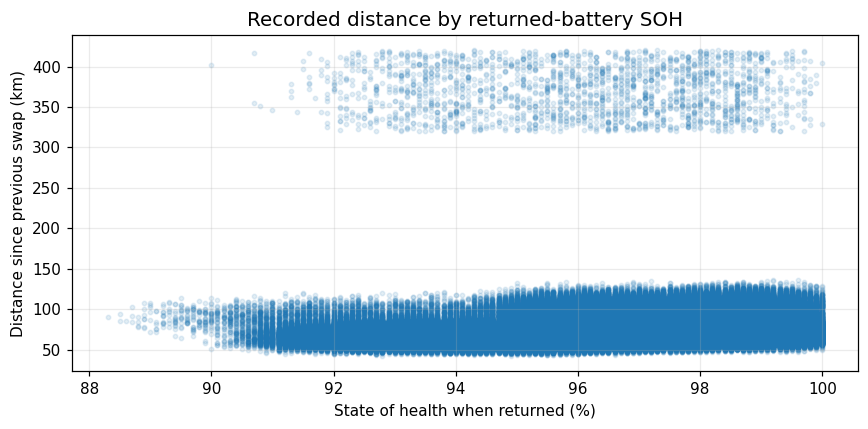

Note: this is an observed range proxy, not a laboratory range test. It may also vary with rider, vehicle and route.


In [9]:
battery_cols = ["battery_id", "pack_type", "supplier", "manufacturing_lot", "manufacture_date", "commission_date", "rated_capacity_kwh", "purchase_cost_inr", "initial_soh_pct", "retired_date", "retirement_reason", "current_soh_pct"]

# km_since_last_swap describes the battery the rider returned, so use battery_in_id here.
returned_battery_events = completed[["event_id", "battery_in_id", "km_since_last_swap", "soh_in_pct"]].merge(
    batteries[battery_cols], left_on="battery_in_id", right_on="battery_id", how="left", validate="many_to_one"
)

print("Battery condition by supplier:")
display(batteries.groupby("supplier").agg(
    packs=("battery_id", "size"),
    retirement_rate=("retired_date", lambda x: x.notna().mean()),
    mean_current_soh=("current_soh_pct", "mean"),
    mean_initial_soh=("initial_soh_pct", "mean")
).round(2))

# Count how often each pack was issued to a rider in the supplied event file.
issue_counts = completed["battery_out_id"].value_counts().rename("observed_issue_count")
battery_usage = batteries[["battery_id", "supplier", "manufacturing_lot", "current_soh_pct"]].merge(
    issue_counts, left_on="battery_id", right_index=True, how="left"
)
battery_usage["observed_issue_count"] = battery_usage["observed_issue_count"].fillna(0)
print("Observed battery issues by supplier:")
display(battery_usage.groupby("supplier").agg(
    packs=("battery_id", "size"),
    mean_observed_issues=("observed_issue_count", "mean"),
    median_observed_issues=("observed_issue_count", "median"),
    mean_current_soh=("current_soh_pct", "mean")
).round(2))

lot_risk = batteries.groupby(["supplier", "manufacturing_lot"]).agg(
    packs=("battery_id", "size"),
    retirement_rate=("retired_date", lambda x: x.notna().mean()),
    mean_current_soh=("current_soh_pct", "mean")
).query("packs >= 30").sort_values("retirement_rate", ascending=False)
print("Lots with at least 30 packs:")
display(lot_risk.head(15).round(3))

# Remove invalid odometer readings before comparing range with event-time SOH.
valid_range = returned_battery_events[
    returned_battery_events["km_since_last_swap"].between(0, 500)
    & returned_battery_events["soh_in_pct"].between(0, 100)
].copy()
valid_range["soh_band"] = pd.cut(valid_range["soh_in_pct"], bins=[0, 70, 80, 90, 100], include_lowest=True)
print("Recorded range by returned-battery SOH band (valid readings only):")
display(valid_range.groupby("soh_band", observed=True).agg(
    swaps=("event_id", "size"),
    mean_range_km=("km_since_last_swap", "mean"),
    median_range_km=("km_since_last_swap", "median")
).round(2))
valid_range.plot.scatter(x="soh_in_pct", y="km_since_last_swap", alpha=0.12, s=8, figsize=(8, 4), title="Recorded distance by returned-battery SOH")
plt.xlabel("State of health when returned (%)")
plt.ylabel("Distance since previous swap (km)")
plt.tight_layout(); plt.show()
print("Note: this is an observed range proxy, not a laboratory range test. It may also vary with rider, vehicle and route.")

## 10. Core question 5 — Pricing and fleet partner economics

I compare realised amounts across tariff codes and time periods, then summarise partner activity, revenue and contribution after estimated recharge-energy cost. This helps distinguish high volume from stronger energy-only contribution per swap.

The available extract ends in August 2024, so it cannot evaluate the 2025 pricing pilot or later contract changes described in the brief. It also lacks the complete cost allocation needed to rank partners by true profitability. I therefore treat these results as a first-pass commercial comparison, not a contract decision on their own.


In [10]:
pricing = completed.groupby(["month","tariff_code"],observed=True).agg(swaps=("event_id","size"),mean_list_price=("list_price_inr","mean"),mean_charged=("amount_charged_inr","mean"),mean_discount=("discount_inr","mean")).round(2)
display(pricing)
city_tariff = completed.groupby(["city","tariff_code"],observed=True).agg(swaps=("event_id","size"),mean_amount_charged=("amount_charged_inr","mean")).reset_index()
display(city_tariff.sort_values(["city","swaps"],ascending=[True,False]).round(2))
partner_economics = completed.groupby("partner_id").agg(swaps=("event_id","size"),revenue_inr=("amount_charged_inr","sum"),energy_cost_inr=("energy_cost_inr","sum"),avg_revenue_per_swap=("amount_charged_inr","mean")).reset_index().merge(partners,on="partner_id",how="left")
partner_economics["contribution_before_fixed_per_swap"] = (partner_economics["revenue_inr"]-partner_economics["energy_cost_inr"])/partner_economics["swaps"]
display(partner_economics[["partner_name","partner_segment","swaps","revenue_inr","avg_revenue_per_swap","contribution_before_fixed_per_swap","discount_pct","discount_pct_after_amendment"]].sort_values("swaps",ascending=False).round(2))
print("Pricing comparisons are descriptive. A credible pilot effect needs a suitable comparison group and pre/post design.")

swaps  mean_list_price  mean_charged  mean_discount
month   tariff_code                                                     
2024-01 PARTNER      70941            65.48         58.67           6.81
        STD          34549            62.42         62.42           0.00
2024-02 PARTNER      71676            65.52         58.70           6.83
        STD          34906            62.46         62.47           0.00
2024-03 PARTNER      79087            65.46         58.63           6.83
        STD          39357            62.43         62.43           0.00
2024-04 PARTNER      81390            65.64         58.81           6.83
        STD          41446            62.34         62.34           0.00
2024-05 PARTNER      84885            65.61         58.78           6.82
        STD          43443            62.15         62.15           0.00
2024-06 PARTNER      88048            65.44         58.63           6.81
        STD          45695            62.18         62.18           0.00
2024-07 PARTNER      99486            71.22         63.79           7.42
        STD          52338            67.50         67.50           0.00
2024-08 PARTNER      73659            71.15         63.72           7.43
        STD          38456            67.50         67.50           0.00

,city,tariff_code,swaps,mean_amount_charged
0,Bengaluru,PARTNER,150624,59.80
1,Bengaluru,STD,71026,63.63
2,Delhi NCR,PARTNER,118009,59.46
3,Delhi NCR,STD,60755,64.00
4,Hyderabad,PARTNER,109922,60.28
5,Hyderabad,STD,62859,63.54
6,Jaipur,PARTNER,75004,59.96
7,Jaipur,STD,41759,63.76
8,Mumbai,PARTNER,92291,60.72
9,Mumbai,STD,47046,63.60


,partner_name,partner_segment,swaps,revenue_inr,avg_revenue_per_swap,contribution_before_fixed_per_swap,discount_pct,discount_pct_after_amendment
2,ZipDrop,quick_commerce,145820,8238949.00,56.50,35.47,12.0,28.0
0,FeastFly,food_delivery,142398,8169809.00,57.37,37.43,10.0,NaN
1,ParcelNest,ecom_logistics,80614,4362001.75,54.11,34.24,15.0,NaN
4,Swiggle Go,food_delivery,67262,3836787.75,57.04,36.88,11.0,NaN
3,CargoTuk,cargo_3w,37322,3525250.60,94.46,51.30,8.0,NaN
6,QuickCart,quick_commerce,37284,2132194.60,57.19,37.95,9.0,NaN
5,RideMitra,bike_taxi,30235,1776827.10,58.77,39.45,6.0,NaN
7,DabbaXpress,food_delivery,24402,1443496.60,59.15,38.99,8.0,NaN
11,UrbanErrand,bike_taxi,24066,1447099.50,60.13,40.38,5.0,NaN
10,LastMileHub,ecom_logistics,21893,1276972.00,58.33,37.55,10.0,NaN


Pricing comparisons are descriptive. A credible pilot effect needs a suitable comparison group and pre/post design.


## 11. Core question 6 — Do new riders return?

For this section, I define a return as another **completed swap within 30 days of the rider's first completed swap**. I keep only riders who have enough observed time for the full 30-day follow-up. This avoids counting a rider as a non-return simply because the dataset ends before their follow-up window is complete.

This measure focuses on riders who achieved a first successful swap. It does not include people who signed up but never completed one; that is a separate activation problem. In the next comparison, I use only events and tickets recorded before the first successful swap, so later problems are not incorrectly used to explain an earlier retention outcome.


In [11]:
# Keep riders who signed up early enough to have 30 days of event history in this extract.
riders_ret = riders.copy()
riders_ret["signup_date"] = pd.to_datetime(riders_ret["signup_date"], errors="coerce")
last_event_ts = analysis["event_ts"].max()
first_event_ts = analysis["event_ts"].min()

eligible_riders = riders_ret[
    riders_ret["signup_date"].between(first_event_ts.normalize(), (last_event_ts - pd.Timedelta(days=30)).normalize())
].copy()

# Find each rider's first completed swap on or after signup.
completed_after_signup = completed[["rider_id", "event_ts", "queue_wait_sec"]].merge(
    eligible_riders[["rider_id", "signup_date"]], on="rider_id", how="inner"
)
completed_after_signup = completed_after_signup[
    (completed_after_signup["event_ts"] >= completed_after_signup["signup_date"])
    & (completed_after_signup["event_ts"] <= completed_after_signup["signup_date"] + pd.Timedelta(days=30))
].sort_values("event_ts")
first_success = completed_after_signup.drop_duplicates("rider_id")[["rider_id", "event_ts", "queue_wait_sec"]].rename(
    columns={"event_ts": "first_success_ts", "queue_wait_sec": "first_success_wait_sec"}
)

# A rider is included in the repeat-use analysis only if the first success has a full 30-day follow-up.
cohort = eligible_riders.merge(first_success, on="rider_id", how="inner")
cohort = cohort[cohort["first_success_ts"] <= last_event_ts - pd.Timedelta(days=30)].copy()

completed_follow = completed[["rider_id", "event_ts"]].merge(
    cohort[["rider_id", "first_success_ts"]], on="rider_id", how="inner"
)
returned_ids = completed_follow[
    (completed_follow["event_ts"] > completed_follow["first_success_ts"])
    & (completed_follow["event_ts"] <= completed_follow["first_success_ts"] + pd.Timedelta(days=30))
]["rider_id"].unique()
cohort["returned_within_30d"] = cohort["rider_id"].isin(returned_ids)

print("Eligible sign-ups with a first completed swap and full follow-up:", f"{len(cohort):,}")
print("Returned for another completed swap within 30 days:", f"{cohort['returned_within_30d'].mean() * 100:.2f}%")
for col in ["vehicle_class", "plan_type", "signup_channel", "home_city"]:
    print("\nRepeat-use rate by", col)
    display(cohort.groupby(col, dropna=False)["returned_within_30d"].agg(["count", "mean"]).assign(
        return_rate_pct=lambda x: x["mean"] * 100
    ).drop(columns="mean").round(2))
print("This measures repeat use after a first successful swap. Riders who never completed a first swap are not part of this repeat-use rate; they should be considered separately as an activation problem.")

Eligible sign-ups with a first completed swap and full follow-up: 4,439
Returned for another completed swap within 30 days: 99.48%

Repeat-use rate by vehicle_class


/tmp/ipykernel_12989/2450051886.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(cohort.groupby(col, dropna=False)["returned_within_30d"].agg(["count", "mean"]).assign(


,count,return_rate_pct
vehicle_class,,
2W,3805,99.58
3W,634,98.90



Repeat-use rate by plan_type


/tmp/ipykernel_12989/2450051886.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(cohort.groupby(col, dropna=False)["returned_within_30d"].agg(["count", "mean"]).assign(


,count,return_rate_pct
plan_type,,
partner_billed,2686,99.48
pay_as_you_go,1234,99.35
prepaid_pack,519,99.81


... (2 outputs left out)

,count,return_rate_pct
signup_channel,,
app_store,961,99.27
field_agent,948,99.47
partner_onboarding,2009,99.55
referral,521,99.62



Repeat-use rate by home_city


,count,return_rate_pct
home_city,,
BLR,16,100.00
Bangalore,13,100.00
Bengaluru,974,99.69
Bombay,11,100.00
Delhi,5,100.00
Delhi NCR,833,99.40
Gurgaon,5,100.00
HYD,8,100.00
Hyd,6,100.00


This measures repeat use after a first successful swap. Riders who never completed a first swap are not part of this repeat-use rate; they should be considered separately as an activation problem.


In [12]:
# For possible retention factors, use only events and tickets recorded before the first successful swap.
# This avoids using later problems to explain an earlier retention outcome.
first_experience = analysis.drop(columns=["signup_date"], errors="ignore").merge(
    cohort[["rider_id", "signup_date", "first_success_ts", "returned_within_30d"]],
    on="rider_id", how="inner"
)
first_experience = first_experience[
    (first_experience["event_ts"] >= first_experience["signup_date"])
    & (first_experience["event_ts"] <= first_experience["first_success_ts"])
].copy()

pre_success = first_experience.groupby("rider_id").agg(
    failed_before_first_success=("failed", "sum"),
    first_recorded_wait_sec=("queue_wait_sec", "first"),
    first_attempt_outcome=("event_type", "first")
).reset_index()

pre_success_tickets = tickets.merge(
    cohort[["rider_id", "signup_date", "first_success_ts"]], on="rider_id", how="inner"
)
pre_success_tickets = pre_success_tickets[
    (pd.to_datetime(pre_success_tickets["created_ts"], errors="coerce") >= pre_success_tickets["signup_date"])
    & (pd.to_datetime(pre_success_tickets["created_ts"], errors="coerce") <= pre_success_tickets["first_success_ts"])
]
ticket_counts_before_success = pre_success_tickets.groupby("rider_id").size().rename("tickets_before_first_success")

root_cause_view = cohort.merge(pre_success, on="rider_id", how="left").merge(
    ticket_counts_before_success, on="rider_id", how="left"
)
root_cause_view[["failed_before_first_success", "tickets_before_first_success"]] = root_cause_view[
    ["failed_before_first_success", "tickets_before_first_success"]
].fillna(0)
root_cause_view["had_failure_before_success"] = root_cause_view["failed_before_first_success"] > 0
root_cause_view["had_ticket_before_success"] = root_cause_view["tickets_before_first_success"] > 0
root_cause_view["wait_group"] = pd.cut(
    root_cause_view["first_success_wait_sec"], bins=[-1, 60, 180, 300, float("inf")],
    labels=["Up to 1 min", "1–3 min", "3–5 min", "Over 5 min"]
)

for factor in ["first_attempt_outcome", "had_failure_before_success", "had_ticket_before_success", "wait_group", "vehicle_class", "plan_type", "signup_channel"]:
    print("\n30-day repeat-use rate by", factor)
    summary = root_cause_view.groupby(factor, dropna=False, observed=True)["returned_within_30d"].agg(
        riders="size", repeat_rate="mean"
    )
    summary["repeat_rate_pct"] = summary["repeat_rate"] * 100
    display(summary.drop(columns="repeat_rate").round(2))

print("These results show which early experiences are associated with later repeat use in this cohort. They do not prove that a failure or ticket caused a rider to leave.")


30-day repeat-use rate by first_attempt_outcome


,riders,repeat_rate_pct
first_attempt_outcome,,
abandoned_queue,92,100.00
cancelled_by_rider,16,100.00
failed_no_charged_battery,147,98.64
failed_system_error,12,100.00
swap_completed,4172,99.50



30-day repeat-use rate by had_failure_before_success


,riders,repeat_rate_pct
had_failure_before_success,,
False,4144,99.49
True,295,99.32



30-day repeat-use rate by had_ticket_before_success


,riders,repeat_rate_pct
had_ticket_before_success,,
False,4427,99.48
True,12,100.00


... (5 outputs left out)

,riders,repeat_rate_pct
plan_type,,
partner_billed,2686,99.48
pay_as_you_go,1234,99.35
prepaid_pack,519,99.81



30-day repeat-use rate by signup_channel


,riders,repeat_rate_pct
signup_channel,,
app_store,961,99.27
field_agent,948,99.47
partner_onboarding,2009,99.55
referral,521,99.62


These results show which early experiences are associated with later repeat use in this cohort. They do not prove that a failure or ticket caused a rider to leave.


## 12. Optional deep dive — What should the next budget support?

I use the earlier results to frame the four budget choices in the brief: more stations, more batteries, a network-wide pricing rollout or exclusivity with the largest fleet partner.

My decision rule is to address a measured constraint first. If a small group of busy stations has persistently high failure rates, reliability work at those sites is a more defensible first move than broad expansion. Additional batteries should be justified by evidence of stock shortages; pricing should be tested through a controlled pilot; and partner exclusivity should consider contribution and operational dependence, not just volume.


## 13. Optional deep dive — Did expansion waves perform differently?

I compare attempts, completed swaps, failure rate and average wait by expansion wave. I read the activity counts alongside the rates because the groups may differ in size, age and operating conditions.

This is a descriptive comparison, not a controlled before-and-after study. The available event period also does not cover the full 2025 expansion wave described in the brief.


In [13]:
display(analysis.groupby('expansion_wave', observed=True).agg(attempts=('event_id','size'), completed=('completed','sum'), failure_rate=('failed','mean'), avg_wait_sec=('queue_wait_sec','mean')).round(4))
print('Interpretation: check the attempt count before comparing waves. A small sample cannot support a confident network-wide conclusion.')


,attempts,completed,failure_rate,avg_wait_sec
expansion_wave,,,,
Launch,1046993,977844,0.0660,242.8392
Wave1_2024H2,1582,1518,0.0405,246.9589


Interpretation: check the attempt count before comparing waves. A small sample cannot support a confident network-wide conclusion.


## 14. Optional deep dive — Which fleet partners look valuable?

I compare partner swap volume, revenue, realised revenue per swap and the energy-only contribution estimate. A large partner may bring substantial volume, but volume alone does not show how much value remains after the measured energy cost.

Battery wear, station rent, maintenance, labour and payment costs are not fully allocated to each partner here. The comparison is therefore useful for identifying questions to ask in a contract review, but it is not a complete partner-profitability ranking.


Partner comparisons use swap volume, revenue, average realised revenue and contribution after estimated recharge-energy cost. They do not include battery wear or allocated station costs, so they are a first-pass comparison. The largest partner by volume is not automatically the most valuable partner.

## 15. Optional deep dive — What themes appear in support comments?

I use a small set of keyword groups to scan rider comments for recurring themes such as battery availability, waiting, payment, connectivity and range. I compare this with the agent-assigned ticket categories.

This is a quick exploratory text check, not a full language model or sentiment analysis. Comments may be written in English or Hinglish, and keyword matches can miss context or count a word used in a different sense. I use the results as prompts for further ticket review rather than as definitive root-cause labels.


In [14]:
tickets['comment_clean'] = tickets['rider_comment'].fillna('').str.lower()
patterns = {'Battery availability / stock':r'battery|charged|stock|available|empty','Queue / waiting':r'wait|queue|line|late|slow','Billing / payment':r'amount|charge|bill|payment|deduct|refund','App / connectivity':r'app|network|offline|signal|connect|error','Range / heat':r'range|km|heat|hot|drain'}
text_summary=[]
for label, pattern in patterns.items():
    text_summary.append({'theme':label,'matching_comments':int(tickets['comment_clean'].str.contains(pattern,regex=True).sum())})
display(pd.DataFrame(text_summary))
display(tickets['category'].value_counts().to_frame('tickets'))


,theme,matching_comments
0,Battery availability / stock,12361
1,Queue / waiting,8618
2,Billing / payment,11890
3,App / connectivity,3847
4,Range / heat,4795


,tickets
category,
no_battery_available,11647
other,9484
low_range,6636
app_issue,5787
long_queue,5731
billing_dispute,4715


## 16. Optional deep dive — What records should be checked?

I bring together the quality flags created earlier: unusual state-of-charge readings, implausible distance values, duplicate event IDs, offline-batch records, telemetry status and battery lot retirement patterns.

The purpose is to identify records or operating areas that deserve a closer look. I do not automatically delete offline-batch events or treat every flagged value as invalid; a removal rule should be supported by a clear matching or validation process.


In [15]:
print('SOC out-of-range rows:', int(analysis['soc_out_of_range_flag'].sum()))
print('Odometer outlier rows:', int(analysis['odometer_outlier_flag'].sum()))
print('Duplicate event IDs:', int(analysis['duplicate_event_flag'].sum()))
print('Offline-batch events:', int(analysis['sync_mode'].eq('offline_batch').sum()))
print('Telemetry status:'); display(telemetry['telemetry_status'].value_counts(dropna=False).to_frame('rows'))
print('Battery supplier/lot retirement anomalies:'); display(lot_risk.head(10))


SOC out-of-range rows: 975
Odometer outlier rows: 2082
Duplicate event IDs: 0
Offline-batch events: 159904
Telemetry status:


,rows
telemetry_status,
ok,1441341
partial,36987
missing,9384


Battery supplier/lot retirement anomalies:


packs  retirement_rate  mean_current_soh
supplier manufacturing_lot                                          
Kyron    KY-2407              480         0.991667         60.986042
         KY-2409              481         0.983368         60.915177
         KY-2408              500         0.978000         61.048400
Amptek   AM-2405               88         0.000000         80.636364
         AM-2403               87         0.000000         81.388506
         AM-2404               71         0.000000         80.940845
         AM-2409              100         0.000000         81.182000
         AM-2410               81         0.000000         80.602469
         AM-2411               73         0.000000         80.949315
         AM-2412               81         0.000000         81.169136

## 17. Findings and operational recommendations

This section brings the analysis back to the business decision. I use the headline figures calculated below, together with the station, service, battery, partner and retention comparisons, to decide what should be investigated first.

The strongest recommendation should be the one that is supported by more than one piece of evidence and can be tested operationally. I separate what the data shows from what I recommend checking next.


### Headline results from the supplied extract

The next cell calculates the figures directly from the joined analysis table. These are the values to use in the report and presentation. They describe only the supplied January–August 2024 extract, not the full period stated in the challenge brief.


In [16]:
# A compact, reproducible summary for the final presentation
summary_start = analysis["event_ts"].min()
summary_end = analysis["event_ts"].max()
attempt_count = len(analysis)
completed_count = int(analysis["completed"].sum())
completion_pct = analysis["completed"].mean() * 100
revenue_total = completed["amount_charged_inr"].sum()
energy_cost_total = completed["energy_cost_inr"].sum()
contribution_proxy = (revenue_total - energy_cost_total) / max(completed_count, 1)
print("VOLTRELAY — VERIFIED EXTRACT SUMMARY")
print("Observed period:", summary_start, "to", summary_end)
print("Swap attempts:", f"{attempt_count:,}")
print("Completed swaps:", f"{completed_count:,}")
print("Completion rate:", f"{completion_pct:.2f}%")
print("Non-completion rate:", f"{100-completion_pct:.2f}%")
print("Completed-swap revenue:", f"₹{revenue_total:,.2f}")
print("Estimated energy cost:", f"₹{energy_cost_total:,.2f}")
print("Energy-only contribution proxy per completed swap:", f"₹{contribution_proxy:,.2f}")
print("\nHighest failure-rate cities (with at least 1,000 attempts):")
city_summary = analysis.groupby("city", observed=True).agg(attempts=("event_id", "size"), failure_rate=("failed", "mean"))
city_summary = city_summary[city_summary["attempts"] >= 1000].sort_values("failure_rate", ascending=False)
display(city_summary.assign(failure_rate_pct=city_summary["failure_rate"]*100).drop(columns="failure_rate").head(5).round(2))
print("\nHighest-volume stations with elevated failure rates (minimum 1,000 attempts):")
display(station_kpis.sort_values(["failure_rate", "attempts"], ascending=[False, False]).head(5).round(3))
print("\nUse this evidence to prioritize a focused station-level reliability intervention before recommending broad expansion. Confirm the exact station cause with inventory, charger and outage checks.")

VOLTRELAY — VERIFIED EXTRACT SUMMARY
Observed period: 2024-01-01 00:00:00 to 2024-08-22 23:55:00
Swap attempts: 1,048,575
Completed swaps: 979,362
Completion rate: 93.40%
Non-completion rate: 6.60%
Completed-swap revenue: ₹60,032,285.90
Estimated energy cost: ₹20,915,572.53
Energy-only contribution proxy per completed swap: ₹39.94

Highest failure-rate cities (with at least 1,000 attempts):


,attempts,failure_rate_pct
city,,
Jaipur,129406,9.77
Delhi NCR,195292,8.46
Hyderabad,187212,7.71
Pune,158349,5.23
Bengaluru,232468,4.65



Highest-volume stations with elevated failure rates (minimum 1,000 attempts):


,station_id,city,location_type,expansion_wave,charger_generation,attempts,failure_rate,avg_wait_sec
61,STN-JAI-138,Jaipur,market,Launch,Gen1,15509,0.104,243.754
24,STN-DEL-037,Delhi NCR,commercial_hub,Launch,Gen1,9681,0.101,239.721
60,STN-JAI-137,Jaipur,commercial_hub,Launch,Gen1,14112,0.099,242.938
62,STN-JAI-139,Jaipur,commercial_hub,Launch,Gen1,11775,0.099,244.722
57,STN-JAI-134,Jaipur,commercial_hub,Launch,Gen1,14042,0.098,241.916



Use this evidence to prioritize a focused station-level reliability intervention before recommending broad expansion. Confirm the exact station cause with inventory, charger and outage checks.


### What I take from these results

The supplied extract contains **1,048,575 attempts**, of which **979,362 were completed**. That gives a **93.40% completion rate** and a **6.60% non-completion rate**. Completed-swap revenue is approximately **₹60.03 million**. After subtracting the estimated recharge-energy cost, the energy-only contribution proxy is **₹39.94 per completed swap**. This is not a full margin or profit figure.

The first operational priority is to use the station and time-of-day comparisons above to identify busy locations where failure and waiting are both elevated, then validate the cause using charged-stock, charger, outage and connectivity records. I would not recommend broad expansion or a network-wide price change based on this extract alone.

The 30-day repeat-use measure applies only to riders with a first successful swap and a complete follow-up window. It should not be compared directly with a company-wide churn rate. The next step is to review the first-attempt and pre-success experience segments together with the eligible rider counts before deciding which early experience deserves intervention.


## 18. Coverage against the six core questions

| Core question | What this notebook provides | What remains limited |
|---|---|---|
| Network performance | Monthly attempts, completed swaps, revenue, failure rate and energy-only contribution estimate | Shorter observation period; several costs excluded |
| Service experience | Outcome mix, waiting time, hour, city, vehicle and station comparisons | Observational patterns; no proof of cause |
| Station and geography | Station ranking, expansion comparison, telemetry summary and ticket rates | No event-level battery turnaround measure |
| Battery and equipment | Supplier/lot health, retirement, issued/returned usage and range comparisons | No complete charge-cycle history or manufacturing-lot experiment |
| Pricing and partners | Tariff comparisons and partner energy-only economics | No 2025 pilot evaluation or full cost allocation |
| Rider retention | 30-day repeat-use cohort and pre-first-success experience comparisons | Short extract; selected cohort; activation and longer-term churn remain open |

**My assessment:** all six questions have been investigated with the supplied fields, but not every sub-question can be fully answered. The remaining gaps are stated rather than filled with assumptions.


## 19. Limitations and interpretation

- The supplied event extract has 1,048,575 rows from 1 January to 22 August 2024. The brief describes 3,877,013 rows through 30 June 2025; this notebook reports only the file I received.
- `attempt_seq` is constant at 1, so it cannot be used to reconstruct retries.
- Offline-batch records are flagged but are not automatically removed; a defensible near-duplicate rule would be needed first.
- Missing telemetry is not treated as zero. Missingness may be related to station connectivity.
- State-of-charge and odometer anomalies are flagged. Range comparisons should be read with this in mind.
- CSAT is missing for most tickets and is not missing at random. Ticket categories are agent-assigned, and keyword matching is only an indicative text scan.
- The contribution estimate subtracts recharge-energy cost only. It excludes battery depreciation, rent, maintenance, labour, payment fees and overhead; it is not net profit or full contribution margin.
- The extract cannot establish the causal effect of the 2025 pricing pilot or confirm the full 18-month retention decline.
- The documented v3.2.0 timestamp issue applies to March–April 2025, outside the event period in this extract, so it cannot be tested here.

A useful business analysis should be clear about both the evidence and its boundaries. These limitations are part of the result, not something to hide.
